In [1]:
try:
    import deepface
except:
    !pip install deepface
    import deepface

from deepface import DeepFace

import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import requests
import urllib3
import io

In [2]:
def get_image_from_url(url, engine="urllib3", format="numpy"):
    if engine.lower() == "urllib3":
        response = urllib3.request("GET", url)
        img = Image.open(io.BytesIO(response.data))
    else:
        response = requests.get(url, stream=True)
        img = Image.open(response.raw)

    if format.lower() == "numpy":
        return np.array(img)
    else:
        return img


def get_face_bbox(result, image_name):
    x0 = result["facial_areas"][image_name]["x"]
    y0 = result["facial_areas"][image_name]["y"]
    x1 = x0 + result["facial_areas"][image_name]["w"]
    y1 = y0 + result["facial_areas"][image_name]["h"]
    return x0, y0, x1, y1

In [3]:
#url_1 = "https://upload.wikimedia.org/wikipedia/commons/thumb/0/0f/Trend_Girls_Photo_Session_%28September_15%2C_2024%29IMG_7861.jpg/1384px-Trend_Girls_Photo_Session_%28September_15%2C_2024%29IMG_7861.jpg"
#url_1 = "https://upload.wikimedia.org/wikipedia/commons/thumb/a/a9/Trend_Girls_Photo_Session_%28September_15%2C_2024%29IMG_9959.jpg/1365px-Trend_Girls_Photo_Session_%28September_15%2C_2024%29IMG_9959.jpg"
#url_2 = "https://upload.wikimedia.org/wikipedia/commons/f/f0/Hitomi_Tanaka%2C_Julia%2C_Minori_Hatsune%2C_Shiori_Kamisaki%2C_Moe_Amatsuka%2C_Anri_Okita%2C_Chinami_It%C5%8D%2C_Ruri_Saij%C5%8D%2C_Kurea_Hasumi%2C_Aika%2C_Riku_Minato%2C_%26_Serina_Hayakawa_at_AVN_Adult_Entertainment_Expo_2016_%2825363552570%29.jpg"


#url_1 = "https://upload.wikimedia.org/wikipedia/commons/thumb/5/56/Donald_Trump_official_portrait.jpg/808px-Donald_Trump_official_portrait.jpg"
#url_2 = "https://upload.wikimedia.org/wikipedia/commons/7/70/Donald_Trump_takes_the_oath_of_office_%282025%29_%28cropped2%29.jpg"


# Demo images.
url_1 = "https://images.pexels.com/photos/8961126/pexels-photo-8961126.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2"
url_2 = "https://images.pexels.com/photos/8961296/pexels-photo-8961296.jpeg?auto=compress&cs=tinysrgb&w=1260&h=750&dpr=2"


img_1 = get_image_from_url(url_1)
img_2 = get_image_from_url(url_2)

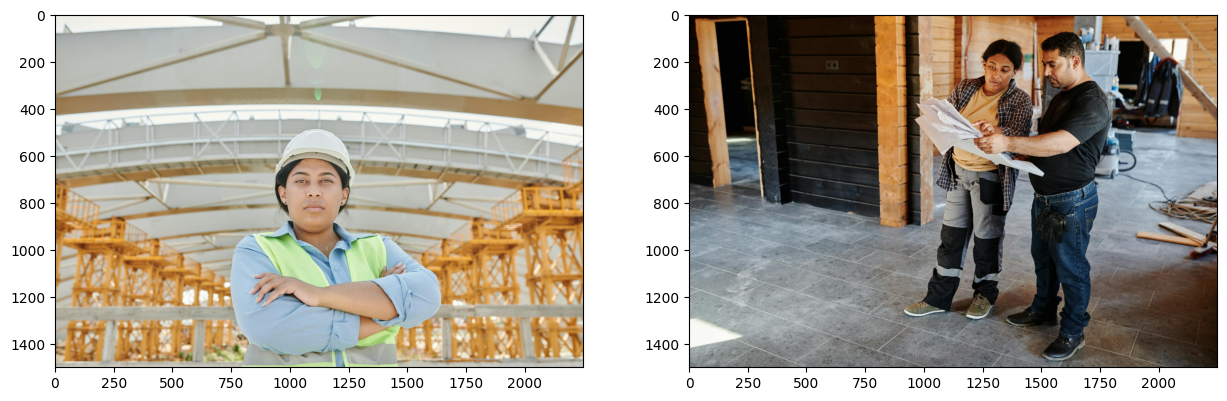

In [4]:
plt.figure(figsize = [15, 5])
plt.subplot(1, 2, 1)
plt.imshow(img_1)
plt.subplot(1, 2, 2)
plt.imshow(img_2)
plt.show()

In [5]:
metrics = ["cosine", "euclidean", "euclidean_l2"]

models = [
  "VGG-Face",     # 0
  "Facenet",      # 1
  "Facenet512",   # 2
  "OpenFace",     # 3
  "DeepFace",     # 4
  "DeepID",       # 5
  "ArcFace",      # 6
  "Dlib",         # 7
  "SFace",        # 8
  "GhostFaceNet", # 9
]

backends = [
  'opencv',      # 0
  'ssd',         # 1
  'dlib',        # 2
  'mtcnn',       # 3
  'fastmtcnn',   # 4
  'retinaface',  # 5
  'mediapipe',   # 6
  'yolov8',      # 7
  'yolov11s',    # 8
  'yolov11n',    # 9
  'yolov11m',    # 10
  'yunet',       # 11
  'centerface',  # 12
]

alignment_modes = [True, False]

In [6]:
# Face verification.
result = DeepFace.verify(
    img_1,
    img_2,
    distance_metric = metrics[0],
    model_name = models[2],
    detector_backend = backends[5],
    align = alignment_modes[0]
)

print("Time elapsed: {:d}s.".format(int(round(result.get("time")))))

Time elapsed: 44s.


In [7]:
result

{'verified': False,
 'distance': 0.3103499108048897,
 'threshold': 0.3,
 'model': 'Facenet512',
 'detector_backend': 'retinaface',
 'similarity_metric': 'cosine',
 'facial_areas': {'img1': {'x': 979,
   'y': 598,
   'w': 242,
   'h': 315,
   'left_eye': (1156, 710),
   'right_eye': (1047, 709)},
  'img2': {'x': 1253,
   'y': 170,
   'w': 125,
   'h': 158,
   'left_eye': (1342, 240),
   'right_eye': (1285, 228)}},
 'time': 43.94}

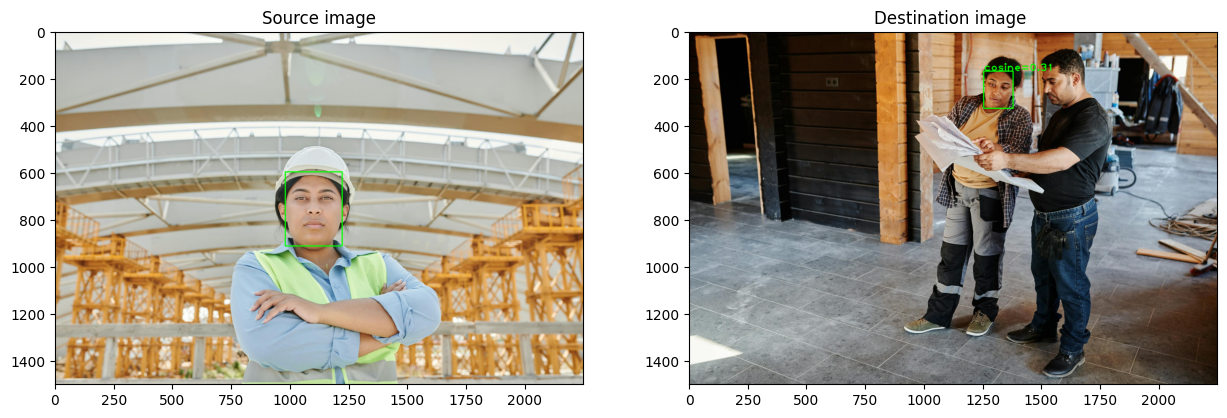

In [8]:
vis_1 = img_1.copy()
vis_2 = img_2.copy()

color = [0, 255, 0]
thickness = 4

x0, y0, x1, y1 = get_face_bbox(result, "img1")
vis_1 = cv2.rectangle(vis_1, [x0, y0], [x1, y1], color=color, thickness=thickness)
x0, y0, x1, y1 = get_face_bbox(result, "img2")
vis_2 = cv2.rectangle(vis_2, [x0, y0], [x1, y1], color=color, thickness=thickness)
vis_2 = cv2.putText(vis_2, "{}={:.2f}".format(result["similarity_metric"], result["distance"]),
                    [x0, y0], color=color, fontFace=cv2.FONT_HERSHEY_PLAIN, fontScale=3, thickness=thickness)

plt.figure(figsize = [15, 5])
plt.subplot(1, 2, 1)
plt.title("Source image")
plt.imshow(vis_1)
plt.subplot(1, 2, 2)
plt.title("Destination image ")
plt.imshow(vis_2)
plt.show()

In [9]:
faces_1 = DeepFace.extract_faces(
  img_path = img_1,
  detector_backend = backends[5],
  align = alignment_modes[0],
)

embeddings_1 = []
for i in range(len(faces_1)):
    facial_area = faces_1[i]["facial_area"]
    x0 = facial_area["x"]
    y0 = facial_area["y"]
    x1 = x0 + facial_area["w"]
    y1 = y0 + facial_area["h"]
    embeddings_1.append(DeepFace.represent(
        img_path=img_1[y0:y1, x0:x1, :],
        model_name=models[2],
        enforce_detection=False,
    ))

In [10]:
faces_2 = DeepFace.extract_faces(
  img_path = img_2,
  detector_backend = backends[5],
  align = alignment_modes[0],
)

embeddings_2 = []
for i in range(len(faces_2)):
    facial_area = faces_2[i]["facial_area"]
    x0 = facial_area["x"]
    y0 = facial_area["y"]
    x1 = x0 + facial_area["w"]
    y1 = y0 + facial_area["h"]
    embeddings_2.append(DeepFace.represent(
        img_path=img_2[y0:y1, x0:x1, :],
        model_name=models[2],
        enforce_detection=False,
    ))

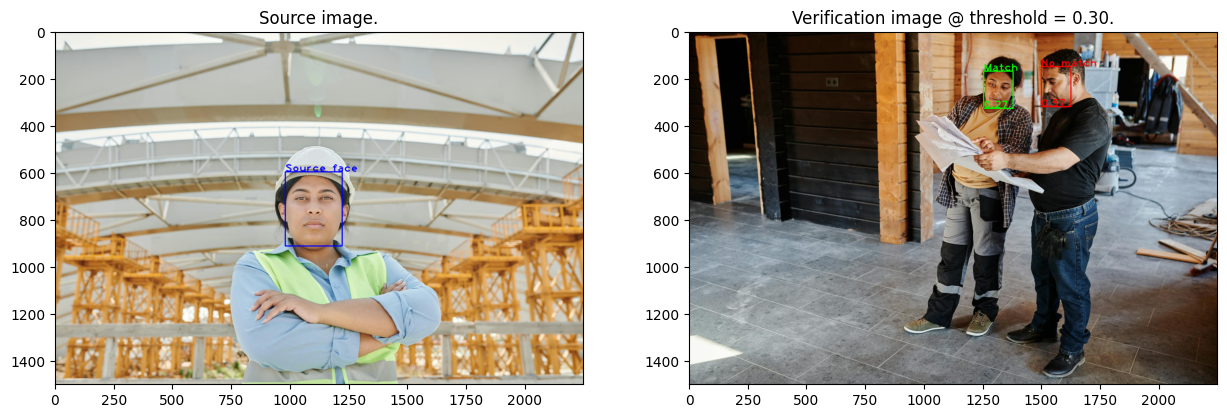

In [15]:
vis_1 = img_1.copy()
vis_2 = img_2.copy()

color_source = [0, 0, 255]
color_success = [0, 255, 0]
color_fail = [255, 0, 0]
thickness = 4
fontScale = 3

threshold = 0.3

facial_area = faces_1[0]["facial_area"]
x0 = facial_area["x"]
y0 = facial_area["y"]
x1 = x0 + facial_area["w"]
y1 = y0 + facial_area["h"]
vis_1 = cv2.rectangle(vis_1, [x0, y0], [x1, y1], color=color_source, thickness=thickness)
vis_1 = cv2.putText(vis_1, "Source face",[x0, y0], color=color_source, fontFace=cv2.FONT_HERSHEY_PLAIN,
                    fontScale=fontScale, thickness=thickness)

for i in range(len(faces_2)):
    facial_area = faces_2[i]["facial_area"]
    x0 = facial_area["x"]
    y0 = facial_area["y"]
    x1 = x0 + facial_area["w"]
    y1 = y0 + facial_area["h"]
    a = np.array(embeddings_1[0][0]["embedding"])
    b = np.array(embeddings_2[i][0]["embedding"])
    similarity = 1 - np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    if similarity <= threshold:
        color = color_success
        text = "Match"
    else:
        color = color_fail
        text = "No match"
    vis_2 = cv2.rectangle(vis_2, [x0, y0], [x1, y1], color=color, thickness=thickness)
    vis_2 = cv2.putText(vis_2, "{}".format(text), [x0, y0], color=color, fontFace=cv2.FONT_HERSHEY_PLAIN,
                        fontScale=fontScale, thickness=thickness)
    vis_2 = cv2.putText(vis_2, "{:.2f}".format(similarity), [x0, y1], color=color, fontFace=cv2.FONT_HERSHEY_PLAIN,
                        fontScale=fontScale, thickness=thickness)


plt.figure(figsize = [15, 5])
plt.subplot(1, 2, 1)
plt.title("Source image.")
plt.imshow(vis_1)
plt.subplot(1, 2, 2)
plt.title("Verification image @ threshold = {:.2f}.".format(threshold))
plt.imshow(vis_2)
plt.show()